# Neural net experiments

**Goal:** see whether a small neural network (scikit-learn's `MLPClassifier`) finds class signal
that carries over to new subjects.

**Background from `ada_boost.ipynb`:** AdaBoost didn't beat the majority baseline on grouped-by-subject
CV, and it predicted all 1s on held-out subjects. The features seem to identify *who* a row came
from more than *what class* it is.

**Why a neural net:** unlike trees, a neural net needs scaled inputs, so we have to choose how to
scale. That makes this a natural place to test the main idea from the AdaBoost notebook: **scaling
each feature within its own subject** to remove each subject's "signature".

No submission in this notebook yet. It only evaluates.

Lab-notebook format: **hypothesis → code → result → interpretation** for each experiment.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, GroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=UserWarning)  # sklearn feature-name warnings

RANDOM_STATE = 42

## 1. Load and preprocess (same steps as `ada_boost.ipynb` section 3)

In [2]:
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")

target = "output"
groups = train["subject"]

def prep(df):
    X = df.drop(columns=[c for c in ["output", "subject"] if c in df])
    X = pd.get_dummies(X, columns=["state"], dtype=int)
    return X

X_full = prep(train)
X_test = prep(test).reindex(columns=X_full.columns, fill_value=0)
y = train[target]

const_cols = X_full.columns[X_full.nunique() <= 1]
X_full = X_full.drop(columns=const_cols)
X_test = X_test.drop(columns=const_cols)
print(f"Dropped {len(const_cols)} constant columns -> {X_full.shape[1]} features")

Dropped 108 constant columns -> 564 features


## 2. Evaluation harness

This is the same harness as the AdaBoost notebook, with one addition: **ROC AUC**.

- **Accuracy** (the competition metric) can sit at the baseline even when a model has *some* signal,
  if the signal is never strong enough to flip a prediction to 0.
- **AUC** measures whether the model *ranks* class-0 rows below class-1 rows, whatever the threshold.
  An AUC of 0.5 is random guessing and 1.0 is a perfect ranking. If the grouped AUC is clearly above
  0.5, there's real signal that threshold tuning could turn into accuracy.

In [3]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gkf = GroupKFold(n_splits=5)
results = []

def evaluate(name, model, X=None):
    X = X_full if X is None else X
    row = {"model": name}
    for cv_name, cv, kw in [("strat", skf, {}), ("group", gkf, {"groups": groups})]:
        s = cross_validate(model, X, y, cv=cv, n_jobs=-1,
                           scoring=["accuracy", "f1_macro", "roc_auc"], **kw)
        row[f"{cv_name}_acc"] = s["test_accuracy"].mean()
        row[f"{cv_name}_f1m"] = s["test_f1_macro"].mean()
        row[f"{cv_name}_auc"] = s["test_roc_auc"].mean()
    results.append(row)
    return pd.Series(row)

evaluate("majority baseline", DummyClassifier(strategy="most_frequent"))

model        majority baseline
strat_acc             0.844895
strat_f1m             0.457964
strat_auc                  0.5
group_acc             0.852051
group_f1m              0.45784
group_auc                  0.5
dtype: object

## 3. Experiment 1: MLP with ordinary (global) scaling

**Hypothesis:** a neural net with standard scaling (mean 0, std 1 for each feature, computed over all
training rows) will act like AdaBoost. It will do fine on subjects it has seen and fall back to
predicting all 1s on new subjects, because global scaling leaves each subject's signature in place.

The scaler sits inside a pipeline, so in each CV fold it's fitted on the training folds only.

In [4]:
def mlp(hidden=(64,), alpha=1e-3):
    return MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, early_stopping=True,
                         max_iter=500, random_state=RANDOM_STATE)

evaluate("MLP (64), global scaling", make_pipeline(StandardScaler(), mlp()))

model        MLP (64), global scaling
strat_acc                    0.845113
strat_f1m                    0.527959
strat_auc                    0.659518
group_acc                    0.837382
group_f1m                    0.465531
group_auc                     0.54741
dtype: object

**Interpretation:** this hypothesis was mostly right. On subjects it has seen, the MLP has real
ranking signal (shuffled AUC 0.66), but on new subjects that drops to 0.55, barely above random.
Grouped accuracy (0.837) is *below* the baseline (0.852). Unlike AdaBoost it does predict some 0s,
but mostly wrongly.

## 4. Experiment 2: MLP with per-subject scaling

**Hypothesis:** if each subject has its own offset and spread (a "signature"), z-scoring every
feature **within each subject** removes it. The model then sees "how unusual is this row *for this
subject*", which should carry over to new subjects. Grouped accuracy and AUC should go up.

**Is this allowed?** Yes. The scaling uses only the feature values of a subject's own rows, never
their labels. For the test set, E and J can be scaled with their own test rows, which needs no
labels either. In grouped CV, the held-out subjects are scaled the same way, so this mirrors the
test situation.

We only scale the continuous sensor features. `phase` and the `state_*` columns are left as they
are, because they describe conditions, not measurements.

In [5]:
cond_cols = ["phase"] + [c for c in X_full.columns if c.startswith("state_")]
sensor_cols = [c for c in X_full.columns if c not in cond_cols]

def per_subject_scale(X, subj):
    X = X.copy()
    g = X[sensor_cols].groupby(subj.values)
    mean = g.transform("mean")
    std = g.transform("std").replace(0, np.nan)
    # A feature that is constant within one subject becomes 0 for that subject
    X[sensor_cols] = ((X[sensor_cols] - mean) / std).fillna(0)
    return X

X_subj = per_subject_scale(X_full, groups)
X_test_subj = per_subject_scale(X_test, test["subject"])  # ready for a later submission

# A final global scaler keeps the condition columns on a similar scale to the rest
evaluate("MLP (64), per-subject scaling", make_pipeline(StandardScaler(), mlp()), X_subj)

model        MLP (64), per-subject scaling
strat_acc                         0.835079
strat_f1m                         0.488764
strat_auc                          0.60982
group_acc                         0.812648
group_f1m                         0.460281
group_auc                         0.490663
dtype: object

**Interpretation:** this hypothesis was wrong. Per-subject scaling made things **worse**: grouped
AUC fell to 0.49 (random) and grouped accuracy to 0.813. So either the class signal isn't a
within-subject change, or scaling within a subject also removed the useful part. One possible
reason: some subjects are almost all one class (K is 100% class 1). For them, "unusual for this
subject" can't mean "class 0".

## 5. Experiment 3: network size and regularisation

**Hypothesis:** with only 11 training subjects, a bigger network will memorise subject-specific
patterns. Stronger L2 regularisation (`alpha`) and smaller layers should carry over better to new
subjects.

This uses whichever scaling did better on grouped AUC in experiments 1 and 2.

In [6]:
res = pd.DataFrame(results).set_index("model")
use_subj = res.loc["MLP (64), per-subject scaling", "group_auc"] > res.loc["MLP (64), global scaling", "group_auc"]
X_best = X_subj if use_subj else X_full
scaling = "per-subject" if use_subj else "global"
print("Using", scaling, "scaling")

grid = []
for hidden in [(16,), (64,), (128, 64)]:
    for alpha in [1e-4, 1e-2, 1.0]:
        s = evaluate(f"MLP {hidden}, alpha={alpha}, {scaling}",
                     make_pipeline(StandardScaler(), mlp(hidden, alpha)), X_best)
        grid.append({"hidden": str(hidden), "alpha": alpha,
                     "group_acc": s.group_acc, "group_auc": s.group_auc})

grid = pd.DataFrame(grid)
grid.pivot(index="hidden", columns="alpha", values="group_auc").round(3)

Using global scaling


alpha,0.0001,0.0100,1.0000
hidden,,,
"(128, 64)",0.590,0.544,0.568
"(16,)",0.517,0.516,0.526
"(64,)",0.551,0.550,0.560


**Interpretation:** all settings are close, with grouped AUC between 0.52 and 0.59. The largest
network with the weakest regularisation, (128, 64) with alpha=0.0001, scores best at 0.59. That's
the opposite of the hypothesis, but the gap is small for a single random seed, so it may be noise.
No setting beats the baseline on grouped accuracy.

## 6. Results so far

In [7]:
pd.DataFrame(results).set_index("model").round(4)

,strat_acc,strat_f1m,strat_auc,group_acc,group_f1m,group_auc
model,,,,,,
majority baseline,0.8449,0.4580,0.5000,0.8521,0.4578,0.5000
"MLP (64), global scaling",0.8451,0.5280,0.6595,0.8374,0.4655,0.5474
"MLP (64), per-subject scaling",0.8351,0.4888,0.6098,0.8126,0.4603,0.4907
"MLP (16,), alpha=0.0001, global",0.8442,0.5391,0.6679,0.8355,0.4665,0.5165
"MLP (16,), alpha=0.01, global",0.8423,0.5415,0.6710,0.8321,0.4614,0.5161
"MLP (16,), alpha=1.0, global",0.8445,0.5403,0.6774,0.8376,0.4608,0.5259
"MLP (64,), alpha=0.0001, global",0.8445,0.5291,0.6606,0.8370,0.4625,0.5506
"MLP (64,), alpha=0.01, global",0.8442,0.5290,0.6606,0.8376,0.4656,0.5505
"MLP (64,), alpha=1.0, global",0.8453,0.5433,0.6833,0.8385,0.4664,0.5605


## 7. Experiment 4: errors and threshold on held-out subjects

**Hypothesis:** even if the model has some ranking signal (grouped AUC > 0.5), the default 0.5
threshold on predicted probability may still predict almost all 1s. Lowering the bar for predicting
0 might raise accuracy.

We get one out-of-fold probability per training row with grouped CV. Each row is then scored by a
model that never saw its subject. We plot accuracy against the threshold.

Best: hidden=(128, 64), alpha=0.0001, scaling=global


Accuracy at 0.5: 0.8174   best: 0.8449 at threshold 0.05


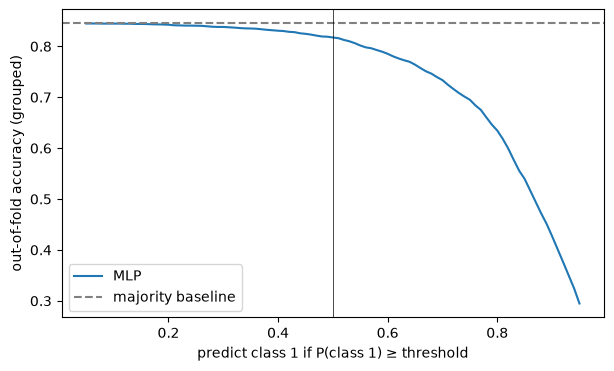

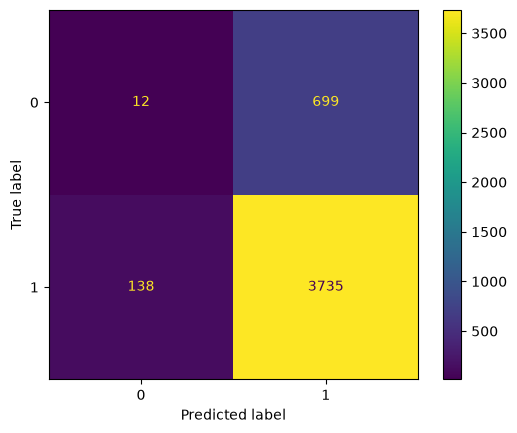

In [8]:
best_row = grid.loc[grid.group_auc.idxmax()]
best_model = make_pipeline(StandardScaler(),
                           mlp(eval(best_row.hidden), best_row.alpha))
print(f"Best: hidden={best_row.hidden}, alpha={best_row.alpha}, scaling={scaling}")

proba_1 = cross_val_predict(best_model, X_best, y, cv=gkf, groups=groups,
                            method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.linspace(0.05, 0.95, 91)
accs = [accuracy_score(y, (proba_1 >= t).astype(int)) for t in thresholds]
best_t = thresholds[int(np.argmax(accs))]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, accs, label="MLP")
ax.axhline((y == 1).mean(), color="grey", ls="--", label="majority baseline")
ax.axvline(0.5, color="black", lw=0.5)
ax.set_xlabel("predict class 1 if P(class 1) ≥ threshold")
ax.set_ylabel("out-of-fold accuracy (grouped)")
ax.legend()
print(f"Accuracy at 0.5: {accuracy_score(y, (proba_1 >= 0.5).astype(int)):.4f}   "
      f"best: {max(accs):.4f} at threshold {best_t:.2f}")

ConfusionMatrixDisplay(confusion_matrix(y, (proba_1 >= 0.5).astype(int))).plot()

**Interpretation:** at threshold 0.5 the out-of-fold accuracy is 0.817. The best threshold is 0.05,
which predicts class 1 for almost every row and gets 0.845, the baseline. So moving the threshold
can't turn the weak AUC (about 0.59) into an accuracy gain: the model's class-0 guesses are wrong
more often than right at every threshold.

## 8. Feature importance (permutation, held-out subjects)

**Hypothesis:** if per-subject scaling helped, the important features should now be ones that change
*within* a subject between class 0 and class 1, rather than ones that tell subjects apart.

Held-out subjects: ['C', 'I']


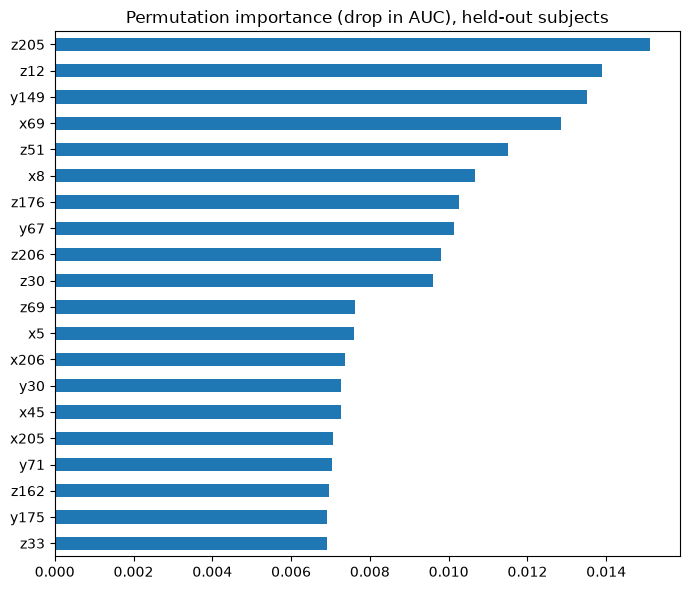

In [9]:
tr_idx, va_idx = next(GroupKFold(n_splits=4).split(X_best, y, groups))
best_model.fit(X_best.iloc[tr_idx], y.iloc[tr_idx])
print("Held-out subjects:", sorted(groups.iloc[va_idx].unique()))

perm = permutation_importance(best_model, X_best.iloc[va_idx], y.iloc[va_idx],
                              scoring="roc_auc", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_best.columns).sort_values(ascending=False)
perm_imp.head(20)[::-1].plot.barh(figsize=(7, 6),
                                  title="Permutation importance (drop in AUC), held-out subjects")
plt.tight_layout()

**Interpretation:** the top features are `z205`, `z12`, `y149`, `x69` and `z51`. Each drops AUC by
only about 0.01–0.015 when shuffled, and about 30 features pass 0.005. So the signal is weak and
spread across all three blocks, with no single dominant feature. There's no overlap with AdaBoost's
top features (`phase`, `x50`, `z207`...), which supports the idea that neither model has found a
stable signal.

We use AUC instead of accuracy for importance. A model that predicts all 1s has an accuracy that
never changes when a feature is shuffled, which is why every feature showed about 0 importance in
the AdaBoost notebook.

## Summary and next steps

**Result:** no neural net setting beats the majority baseline on grouped accuracy. The best grouped
AUC is 0.59, which is weak signal, and threshold tuning can't turn it into accuracy.

**What we learned:**
- Per-subject scaling **hurt** (grouped AUC 0.49). The "remove each subject's signature" idea from
  the AdaBoost notebook doesn't work in its simple form.
- The MLP has more ranking signal than AdaBoost on seen subjects (shuffled AUC about 0.69), but most
  of it doesn't carry over to new subjects.

**Next steps:**
1. Check how the per-subject scaling interacts with subjects that are almost all one class. For
   example, try scaling by `subject` × `phase`, or scaling only a subset of features.
2. Average several random seeds before trusting the size/alpha differences in section 5.
3. Feature selection: train only on the ~30 features with positive importance in section 8, and
   check whether grouped AUC improves.
